# TASS projekt 1 - część B

Patryk Stachyra

In [13]:
import networkx as nx
import numpy as np
from scipy.stats import linregress
from matplotlib import pyplot as plt

# wczytanie pliku
G = nx.read_edgelist("0.txt", create_using=nx.MultiGraph)

## Pierwotna sieć

In [2]:
# rząd
print(f'Rząd: {nx.number_of_nodes(G)}')

# rozmiar
print(f'Rozmiar: {nx.number_of_edges(G)}')

Rząd: 64738
Rozmiar: 258236


## Usunięcie pętli i duplikatów krawędzi

In [3]:
# usunięcie pętli
G.remove_edges_from(nx.selfloop_edges(G))

# usunięcie duplikatów - nowy graf
G_simple = nx.Graph(G)

# rząd
print(f'Rząd: {nx.number_of_nodes(G_simple)}')

# rozmiar
print(f'Rozmiar: {nx.number_of_edges(G_simple)}')

Rząd: 64738
Rozmiar: 242408


## Największa składowa wspólna

In [4]:
# wyznaczenie największej składowej wspólnej
largest_cc = max(nx.connected_components(G_simple), key=len)
GCC = G_simple.subgraph(largest_cc).copy()

# rząd
print(f'Rząd: {nx.number_of_nodes(GCC)}')

# rozmiar
print(f'Rozmiar: {nx.number_of_edges(GCC)}')

Rząd: 64268
Rozmiar: 242157


## Rozkład stopni wierzchołków i dopełnienie dystrybuanty

In [18]:
# lista stopni wierzchołków
degrees = [d for n, d in GCC.degree()]

# prawdopodobieństwo wystąpienia danego stopnia
degree_counts = np.bincount(degrees)
pdf = degree_counts / len(degrees)
k_values = np.arange(len(degree_counts))

# dopełnienie dystrybuanty
ccdf = np.array([np.sum(pdf[i:]) for i in range(len(pdf))])

## Wykres

Współczynnik rozkładu potęgowego (rozkład stopni wierzchołków): -2.09222481927863
Współczynnik rozkładu potęgowego (dopełnienie dystrybuanty): -1.911445593853442


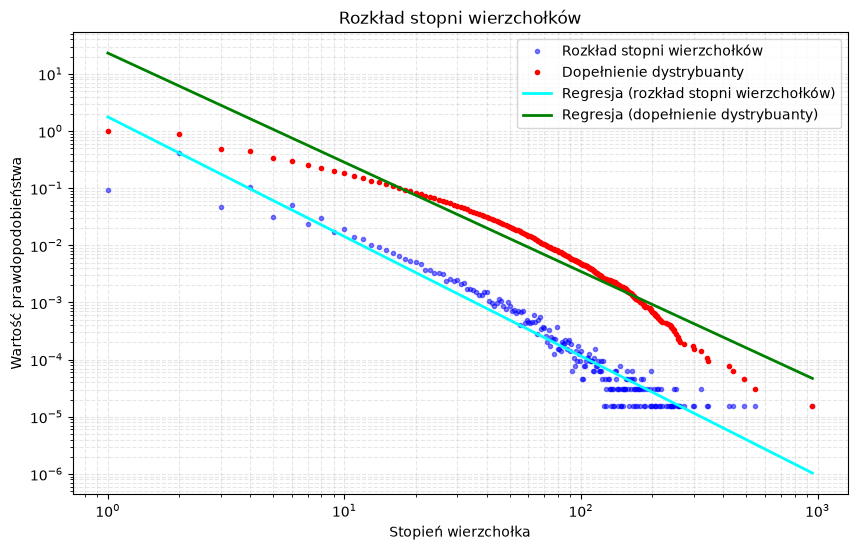

In [30]:
# odrzucenie zerowych prawdopodobieństw
valid = pdf > 0
k_valid = k_values[valid]
pdf_valid = pdf[valid]
ccdf_valid = ccdf[valid]

# logarytm
log_k = np.log10(k_valid)
log_pdf = np.log10(pdf_valid)
log_ccdf = np.log10(ccdf_valid)

# regresja liniowa
slope_pdf, intercept_pdf, _, _, _ = linregress(log_k, log_pdf)
slope_ccdf, intercept_ccdf, _, _, _ = linregress(log_k, log_ccdf)
print(f'Współczynnik rozkładu potęgowego (rozkład stopni wierzchołków): {slope_pdf}')
print(f'Współczynnik rozkładu potęgowego (dopełnienie dystrybuanty): {slope_ccdf}')
trend_pdf = 10 ** (slope_pdf * log_k + intercept_pdf)
trend_ccdf = 10 ** (slope_ccdf * log_k + intercept_ccdf)

# rysowanie wykresu
plt.figure(figsize=(10, 6))
plt.plot(k_valid, pdf_valid, marker='.', linestyle='none', color='blue', alpha=0.5, label='Rozkład stopni wierzchołków')
plt.plot(k_valid, ccdf_valid, marker='.', linestyle='none', color='red', label='Dopełnienie dystrybuanty')
plt.plot(k_valid, trend_pdf, color='cyan', linestyle='-', linewidth=2, label=f'Regresja (rozkład stopni wierzchołków)')
plt.plot(k_valid, trend_ccdf, color='green', linestyle='-', linewidth=2, label=f'Regresja (dopełnienie dystrybuanty)')

plt.xscale('log')
plt.yscale('log')
plt.title('Rozkład stopni wierzchołków')
plt.xlabel('Stopień wierzchołka')
plt.ylabel('Wartość prawdopodobieństwa')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.3)

plt.savefig('zad_6.png', bbox_inches='tight')
plt.show()